<a href="https://colab.research.google.com/github/tabassumakter007/Machine-learning-classification-project/blob/main/notebooks/Mushroom_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

df = pd.read_csv("/content/drive/MyDrive/research stuff/class/classification/mushroom_classification.csv")



# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# First five rows
display(df.head())

# Last five rows
display(df.tail())

# Random five rows
display(df.sample(5, random_state=42))

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
df.info()

# Descriptive statistics for categorical features
display(df.describe(include="all").T)



Number of rows: 8124
Number of columns: 23


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,c,l


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
1971,e,f,f,n,f,n,f,w,b,h,...,f,w,w,p,w,o,e,n,s,g
6654,p,f,s,e,f,y,f,c,n,b,...,s,p,p,p,w,o,e,w,v,l
5606,p,x,y,n,f,f,f,c,n,b,...,s,w,p,p,w,o,e,w,v,l
3332,e,f,y,g,t,n,f,c,b,n,...,s,g,p,p,w,o,p,n,y,d
6988,p,f,s,e,f,s,f,c,n,b,...,s,p,p,p,w,o,e,w,v,l



Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing     

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [ ]:

# Missing values in each column
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Count", ascending=False))

# Total missing values
print("Total missing values:", df.isnull().sum().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check special missing-value markers
for col in df.select_dtypes(include="object").columns:
    question_marks = (df[col] == "?").sum()
    if question_marks > 0:
        print(f"{col}: {question_marks} '?' values")


,Missing Count,Missing Percentage
class,0,0.0
cap-shape,0,0.0
cap-surface,0,0.0
cap-color,0,0.0
bruises,0,0.0
odor,0,0.0
gill-attachment,0,0.0
gill-spacing,0,0.0
gill-size,0,0.0
gill-color,0,0.0


Total missing values: 0
Duplicate rows: 0
stalk-root: 2480 '?' values


Target value counts:


,count
class,
e,4208
p,3916



Target percentages:


,Percentage
class,
e,51.8
p,48.2


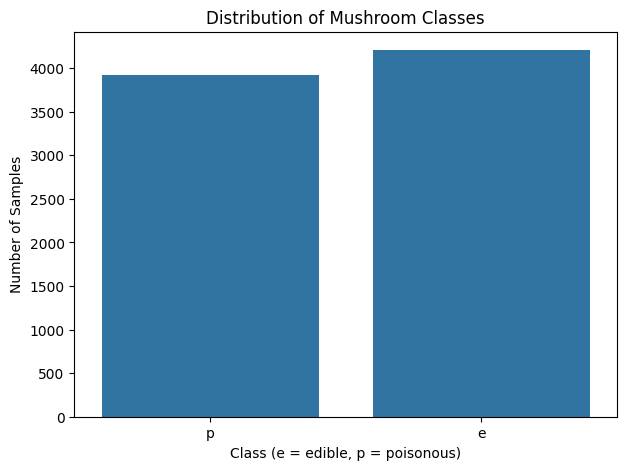

In [ ]:

print("Target value counts:")
display(df["class"].value_counts())

print("\nTarget percentages:")
display(
    (df["class"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="class")
plt.title("Distribution of Mushroom Classes")
plt.xlabel("Class (e = edible, p = poisonous)")
plt.ylabel("Number of Samples")
plt.show()


,Unique Categories
gill-color,12
cap-color,10
odor,9
stalk-color-below-ring,9
spore-print-color,9
stalk-color-above-ring,9
habitat,7
cap-shape,6
population,6
stalk-root,5


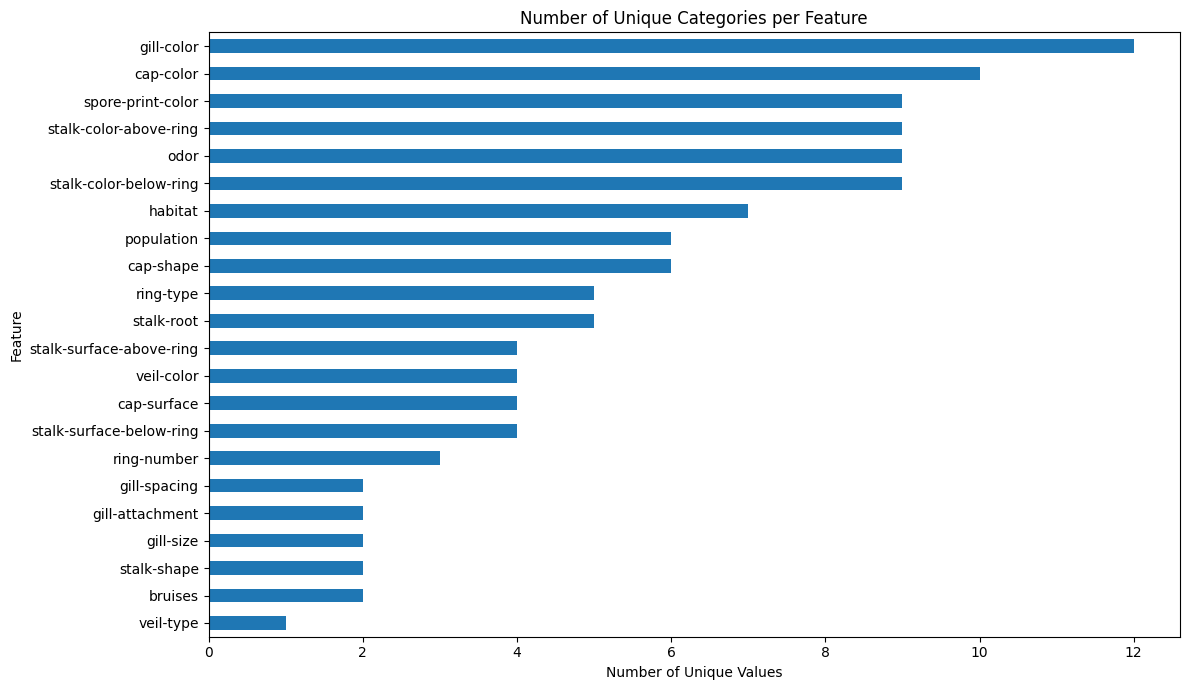

In [ ]:

# Number of unique categories per feature
unique_counts = df.nunique().sort_values(ascending=False)

display(unique_counts.to_frame("Unique Categories"))

plt.figure(figsize=(12, 7))
unique_counts.drop("class", errors="ignore").sort_values().plot(
    kind="barh"
)
plt.title("Number of Unique Categories per Feature")
plt.xlabel("Number of Unique Values")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# **preprocessing**

In [ ]:

# Work on a copy of the original dataset
df_clean = df.copy()

# Convert '?' markers into actual missing values
df_clean.replace("?", np.nan, inplace=True)

# Check missing values
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Count", ascending=False
    )
)

print("Total missing values:", df_clean.isnull().sum().sum())


,Missing Count,Missing Percentage
stalk-root,2480,30.53
cap-shape,0,0.00
class,0,0.00
cap-color,0,0.00
bruises,0,0.00
odor,0,0.00
cap-surface,0,0.00
gill-attachment,0,0.00
gill-spacing,0,0.00
gill-color,0,0.00


Total missing values: 2480


In [ ]:

# Fill missing categorical values with each column's mode
for col in df_clean.columns:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode(dropna=True)[0]
        df_clean[col] = df_clean[col].fillna(mode_value)

print("Missing values after handling:")
print(df_clean.isnull().sum().sum())

print("Dataset shape:", df_clean.shape)


Missing values after handling:
0
Dataset shape: (8124, 23)


In [ ]:

print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining '?' markers:", (df_clean == "?").sum().sum())

display(df_clean.head())


Remaining missing values: 0
Remaining '?' markers: 0


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


# **split and encoding**

In [ ]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=["class"])
y = df_clean["class"].map({"e": 0, "p": 1})

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (6499, 22)
Testing features: (1625, 22)
Training target: (6499,)
Testing target: (1625,)

Training class distribution:
class
0    0.518
1    0.482
Name: proportion, dtype: float64

Testing class distribution:
class
0    0.518
1    0.482
Name: proportion, dtype: float64


In [ ]:

import pandas as pd

# Fit one-hot encoding on training data
X_train_encoded = pd.get_dummies(
    X_train,
    dtype=int
)

# Apply the same columns to test data
X_test_encoded = pd.get_dummies(
    X_test,
    dtype=int
).reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

display(X_train_encoded.head())


Encoded training shape: (6499, 116)
Encoded testing shape: (1625, 116)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
5249,0,0,1,0,0,0,0,0,0,1,...,0,0,1,0,1,0,0,0,0,0
5781,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
7586,1,0,0,0,0,0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,0
6181,0,0,1,0,0,0,0,0,1,0,...,0,1,0,1,0,0,0,0,0,0
7338,0,0,0,1,0,0,0,0,0,1,...,0,1,0,0,0,0,0,1,0,0



Original Dataset - Value Counts:


,Count,Percentage (%)
class,,
Edible,4208,51.8
Poisonous,3916,48.2



Training Set - Value Counts:


,Count,Percentage (%)
class,,
Edible,3366,51.79
Poisonous,3133,48.21



Testing Set - Value Counts:


,Count,Percentage (%)
class,,
Edible,842,51.82
Poisonous,783,48.18


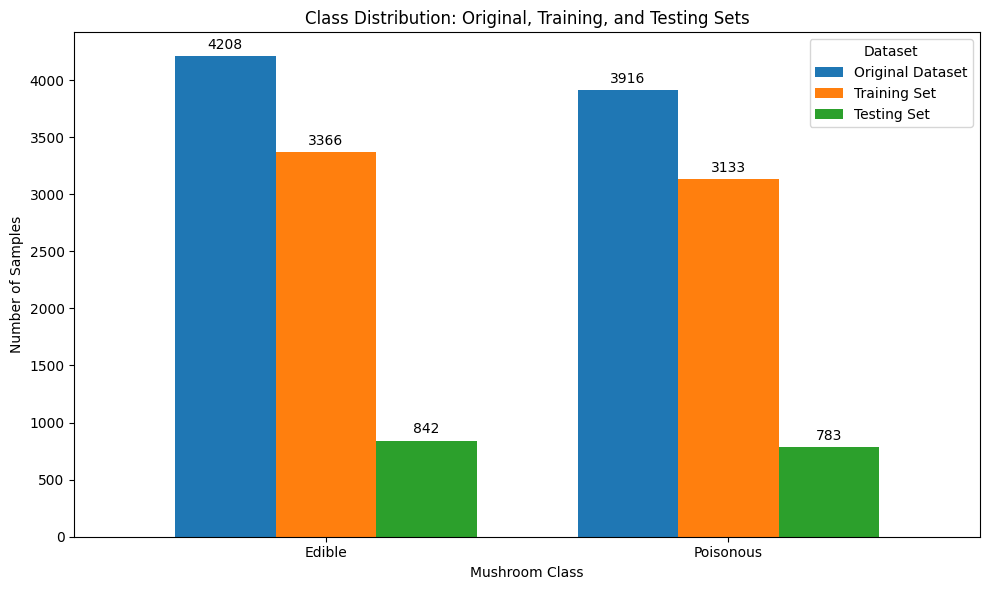

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Class distributions
distributions = {
    "Original Dataset": df_clean["class"].map({"e": "Edible", "p": "Poisonous"}),
    "Training Set": y_train.map({0: "Edible", 1: "Poisonous"}),
    "Testing Set": y_test.map({0: "Edible", 1: "Poisonous"})
}

# Display value counts and percentages
for name, labels in distributions.items():
    print(f"\n{name} - Value Counts:")
    counts = labels.value_counts().reindex(
        ["Edible", "Poisonous"], fill_value=0
    )
    percentages = labels.value_counts(normalize=True).reindex(
        ["Edible", "Poisonous"], fill_value=0
    ) * 100

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages.round(2)
    })
    display(summary)

# Prepare counts for plotting
plot_data = pd.DataFrame({
    name: labels.value_counts().reindex(
        ["Edible", "Poisonous"], fill_value=0
    )
    for name, labels in distributions.items()
})

# Grouped bar plot
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Class Distribution: Original, Training, and Testing Sets")
plt.xlabel("Mushroom Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend(title="Dataset")

# Show count labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


# **models and training**

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42),

    "AdaBoost": AdaBoostClassifier(random_state=42),

    "Gaussian Naive Bayes": GaussianNB(),

    "HistGradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    )
}

print(f"Total models defined: {len(models)}")
for i, name in enumerate(models, 1):
    print(f"{i}. {name}")


Total models defined: 10
1. Logistic Regression
2. KNN
3. SVM
4. Decision Tree
5. Random Forest
6. Extra Trees
7. Gradient Boosting
8. AdaBoost
9. Gaussian Naive Bayes
10. HistGradient Boosting


In [ ]:

# BLOCK 2: TRAIN ALL MODELS

import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

results = {}
training_summary = []

for name, model in models.items():
    print(f"Training: {name}...")
    start_time = time.time()

    model.fit(X_train_encoded, y_train)

    y_pred = model.predict(X_test_encoded)
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    training_summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "Training Time (sec)": round(time.time() - start_time, 2)
    })

print("\nAll models trained successfully!")

summary_df = pd.DataFrame(training_summary)
summary_df = summary_df.sort_values(
    by="ROC AUC", ascending=False
).reset_index(drop=True)

display(summary_df.round(4))


Training: Logistic Regression...
Training: KNN...
Training: SVM...
Training: Decision Tree...
Training: Random Forest...
Training: Extra Trees...
Training: Gradient Boosting...
Training: AdaBoost...
Training: Gaussian Naive Bayes...
Training: HistGradient Boosting...

All models trained successfully!


,Model,Accuracy,F1 Score,ROC AUC,Training Time (sec)
0,Logistic Regression,1.0000,1.0000,1.0000,0.40
1,KNN,0.9988,0.9987,1.0000,0.69
2,SVM,0.9988,0.9987,1.0000,17.61
3,Decision Tree,1.0000,1.0000,1.0000,0.05
4,Random Forest,1.0000,1.0000,1.0000,1.18
5,Extra Trees,1.0000,1.0000,1.0000,1.23
6,Gradient Boosting,0.9988,0.9987,1.0000,1.72
7,AdaBoost,0.9982,0.9981,1.0000,0.50
8,HistGradient Boosting,1.0000,1.0000,1.0000,0.95
9,Gaussian Naive Bayes,0.9569,0.9571,0.9963,0.03



MODEL: Logistic Regression
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



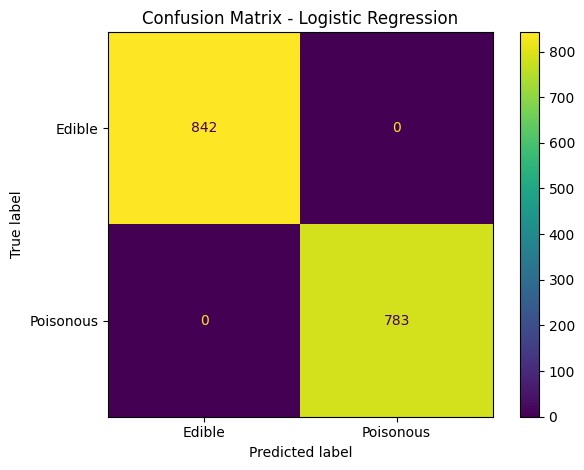


MODEL: KNN
              precision    recall  f1-score   support

      Edible     0.9976    1.0000    0.9988       842
   Poisonous     1.0000    0.9974    0.9987       783

    accuracy                         0.9988      1625
   macro avg     0.9988    0.9987    0.9988      1625
weighted avg     0.9988    0.9988    0.9988      1625



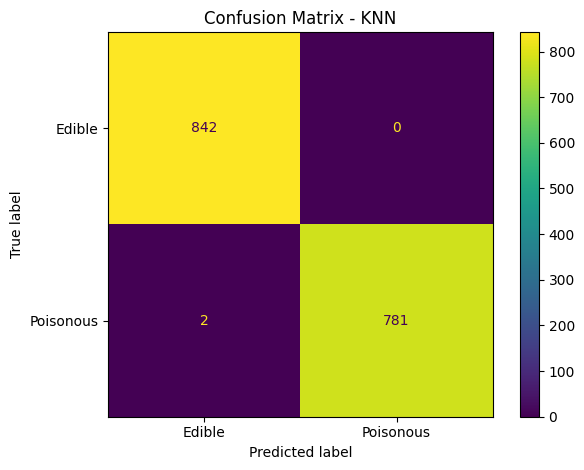


MODEL: SVM
              precision    recall  f1-score   support

      Edible     0.9976    1.0000    0.9988       842
   Poisonous     1.0000    0.9974    0.9987       783

    accuracy                         0.9988      1625
   macro avg     0.9988    0.9987    0.9988      1625
weighted avg     0.9988    0.9988    0.9988      1625



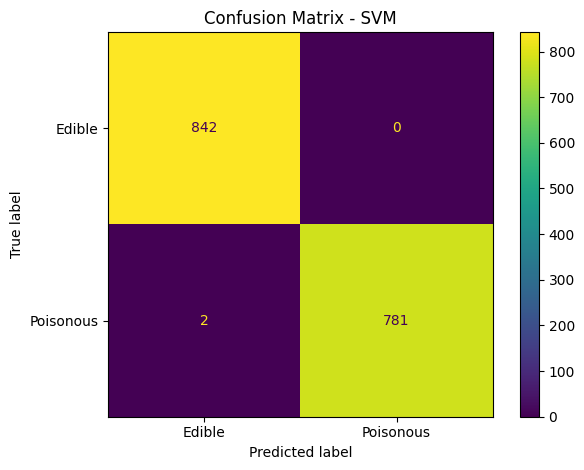


MODEL: Decision Tree
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



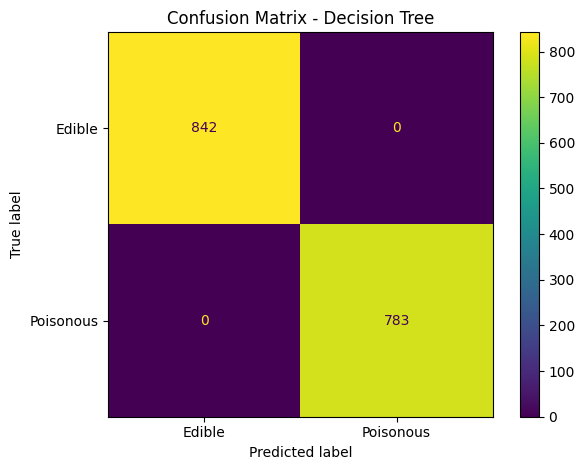


MODEL: Random Forest
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



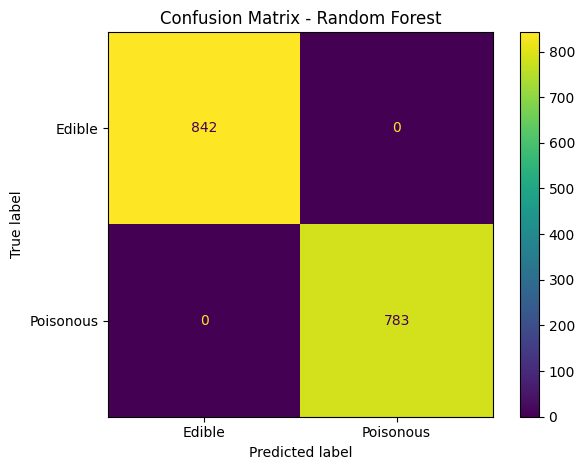


MODEL: Extra Trees
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



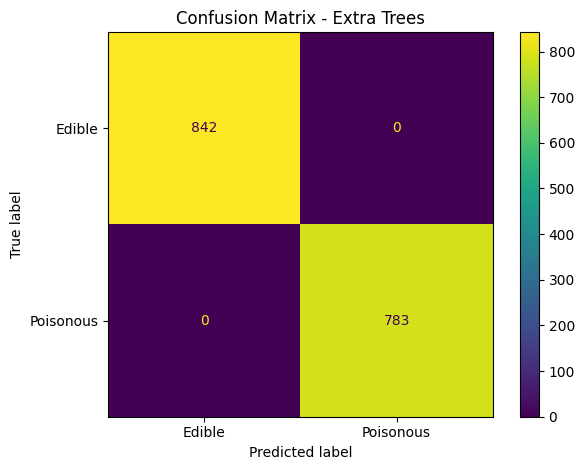


MODEL: Gradient Boosting
              precision    recall  f1-score   support

      Edible     0.9976    1.0000    0.9988       842
   Poisonous     1.0000    0.9974    0.9987       783

    accuracy                         0.9988      1625
   macro avg     0.9988    0.9987    0.9988      1625
weighted avg     0.9988    0.9988    0.9988      1625



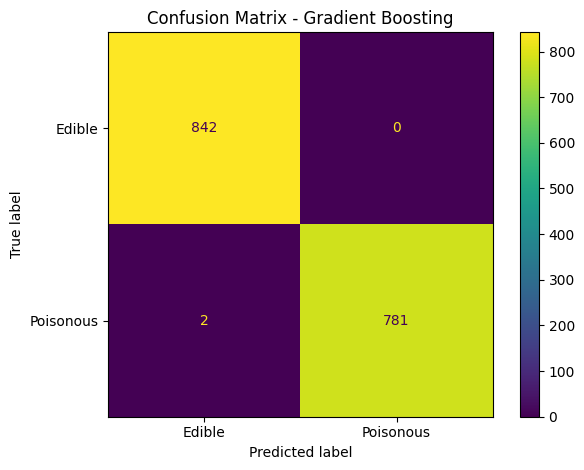


MODEL: AdaBoost
              precision    recall  f1-score   support

      Edible     0.9964    1.0000    0.9982       842
   Poisonous     1.0000    0.9962    0.9981       783

    accuracy                         0.9982      1625
   macro avg     0.9982    0.9981    0.9982      1625
weighted avg     0.9982    0.9982    0.9982      1625



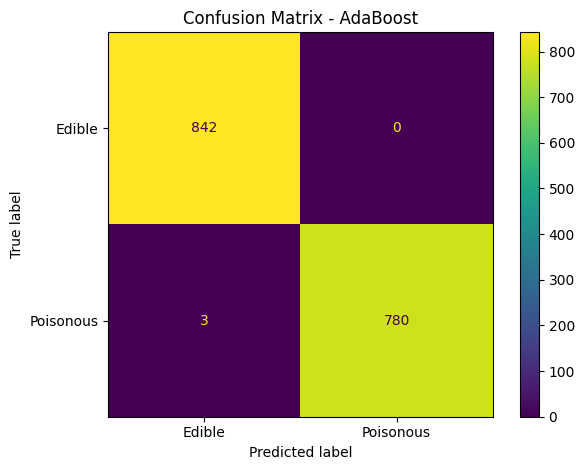


MODEL: Gaussian Naive Bayes
              precision    recall  f1-score   support

      Edible     0.9974    0.9192    0.9567       842
   Poisonous     0.9199    0.9974    0.9571       783

    accuracy                         0.9569      1625
   macro avg     0.9587    0.9583    0.9569      1625
weighted avg     0.9601    0.9569    0.9569      1625



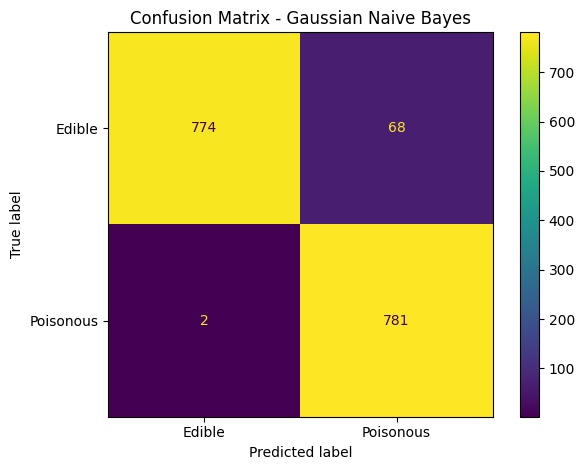


MODEL: HistGradient Boosting
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



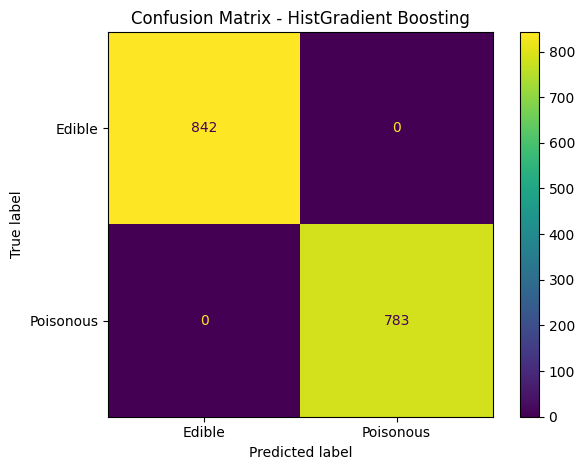

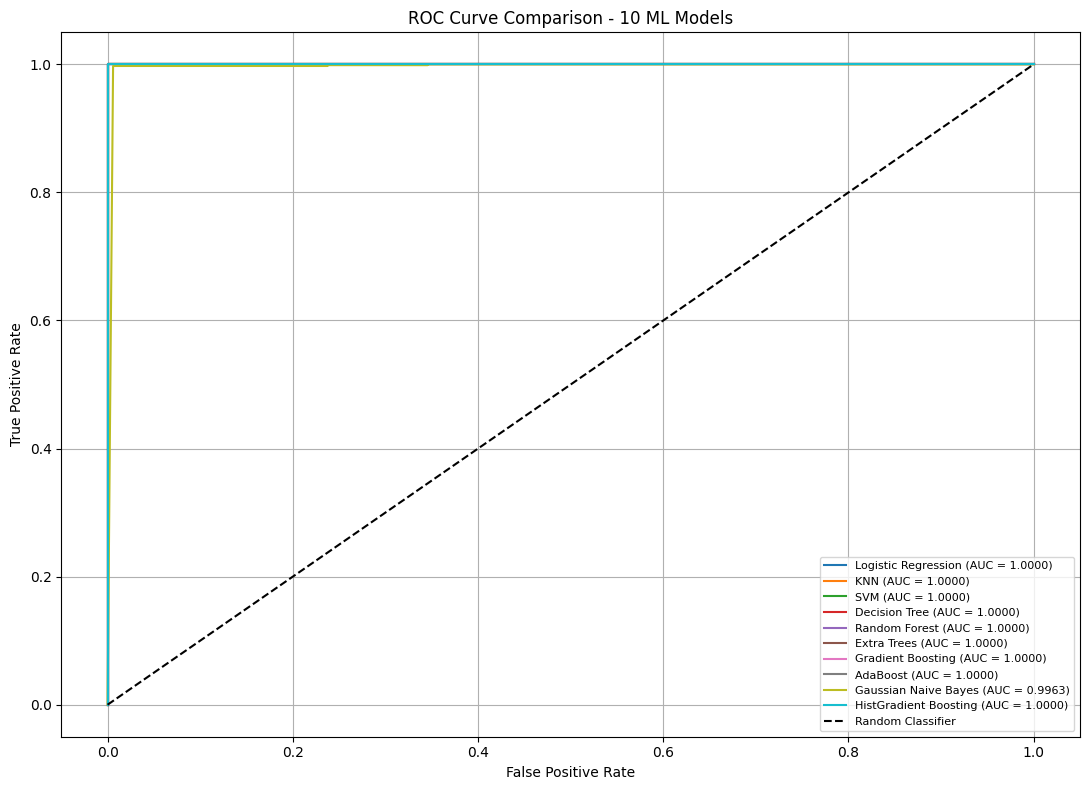

In [ ]:

# BLOCK 3: MODEL EVALUATION

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Classification reports and confusion matrices
for name, result in results.items():
    print("\n" + "=" * 65)
    print(f"MODEL: {name}")
    print("=" * 65)

    print(classification_report(
        y_test,
        result["y_pred"],
        labels=[0, 1],
        target_names=["Edible", "Poisonous"],
        zero_division=0,
        digits=4
    ))

    cm = confusion_matrix(
        y_test, result["y_pred"], labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Edible", "Poisonous"]
    )

    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


# Combined ROC curves
plt.figure(figsize=(11, 8))

for name, result in results.items():
    fpr, tpr, _ = roc_curve(y_test, result["y_prob"])
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - 10 ML Models")
plt.legend(loc="lower right", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()
